# ECG × QoE 

Testa se o ECG prevê a QoE pós-vídeo (QoEP) e a QoE contínua (QoEC) 

In [ ]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import neurokit2 as nk
import shap
import torch
from torch import nn
from scipy import signal, stats
from scipy.stats import expon, randint
from sklearn.model_selection import StratifiedKFold, GroupKFold, GroupShuffleSplit, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import SMOTE

DATA_ROOT = Path('.')
ECG_DIR = DATA_ROOT / 'Physiological_Data/ECG/Raw_ECG_data'
QOEC_DIR = DATA_ROOT / 'QoE_Annotation_Data/Continuous_QoE_Score'
MOS_CSV = DATA_ROOT / 'QoE_Annotation_Data/Post_Video_QoE_Score/post_video_mos_ratings.csv'
ARQ_SESSAO = DATA_ROOT / 'ecg_features_sessao.csv'
ARQ_JANELA = DATA_ROOT / 'ecg_features_janela.csv'

SEED = 42
SESSOES = [(p, v) for p in range(1, 33) for v in range(1, 41)]

## 1. Processamento ECG

- Processando do zero pois os dados a partir do Kubios faltavam dados de 3 participantes + O arquivo do Kubios só tem HRV, sem as ondas P-QRS-T. E foram justamente as features morfológicas que apareceram mais no artigo do QoMEX, que foi usado como base.
- 130 amostras por segundo, com cerca de 30 s por vídeo.
- Em alguns participantes o sinal veio invertido, provavelmente pela posição da cinta. Os autores nos dois artigos justificam o uso de um dataset em detrimento do outro pq um tem ECG invertido. Não sabia muito bem como prosseguir e decidi a polaridade por participante, pela maioria das 40 sessões, e não sessão por sessão. Saíram invertidos P8, P11, P13, P17, P19 e P32.
- A QoEC tem as mesmas linhas do arquivo de movimento de cabeça; por isso o tempo de cada amostra é distribuído uniformemente na duração do ECG.
- Zeros iniciais viram NaN.

In [2]:
def ler_ecg(p, v):
    return pd.read_csv(ECG_DIR / f'ecg_P{p}_V{v}.csv')['ECG'].to_numpy(float)


def ler_qoec(p, v):
    arquivo = next(QOEC_DIR.glob(f'RCQoE_P{p}_V{v}_*.txt'))
    q = pd.read_csv(arquivo, sep=';', usecols=[2]).iloc[:, 0].to_numpy(float)
    q[:np.argmax(q != 0) if (q != 0).any() else len(q)] = np.nan
    return q


def processar_ecg(x, invertido):
    limpo = nk.ecg_clean(-x if invertido else x, sampling_rate=FS)
    _, info = nk.ecg_peaks(limpo, sampling_rate=FS, correct_artifacts=True)
    _, ondas = nk.ecg_delineate(limpo, info['ECG_R_Peaks'], sampling_rate=FS, method='peak')
    return limpo, info['ECG_R_Peaks'], ondas

In [4]:
invertido = {p: np.mean([nk.ecg_invert(ler_ecg(p, v), sampling_rate=FS)[1] for v in range(1, 41)]) > 0.5
             for p in range(1, 33)}
print('Participantes com ECG invertido:', [p for p, inv in invertido.items() if inv])

Participantes com ECG invertido: [8, 11, 13, 17, 19, 32]


<img src="1_ondas_amplitudes.png" width="500"> <img src="2_intervalos.png" width="500">
<img src="3_hrv_janelas.png" width="500">

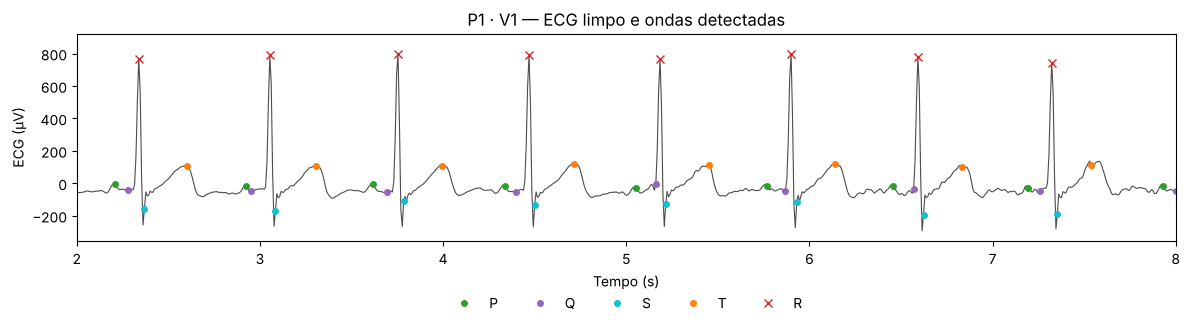

In [ ]:
FS = 130 # a descrição do dataset diz 130 Hz para o Polar H10

limpo, r, ondas = processar_ecg(ler_ecg(1, 1), invertido[1])
t = np.arange(len(limpo)) / FS

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(t, limpo, lw=0.8, color='0.3')
for onda, cor in [('P', 'tab:green'), ('Q', 'tab:purple'), ('S', 'tab:cyan'), ('T', 'tab:orange')]:
    idx = np.array(ondas[f'ECG_{onda}_Peaks'], float)
    idx = idx[~np.isnan(idx)].astype(int)
    ax.plot(t[idx], limpo[idx], 'o', ms=4, color=cor, label=onda)
ax.plot(t[r], limpo[r], 'x', color='tab:red', label='R')
ax.set(xlim=(2, 8), xlabel='Tempo (s)', ylabel='ECG (µV)', title='P1 · V1 — ECG limpo e ondas detectadas')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.savefig('fig_ecg_delineacao.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Features

- **Por sessão (QoMEX 2024):** morfologia P-QRS-T e HRV no vídeo inteiro.
- **Por janela (IEEE Access 2025):** 19 estatísticas em janelas de 3 s com 50% de sobreposição (18 janelas), mais a FC e a QoEC média de cada janela.

In [ ]:
def features_morfologia(limpo, r, ondas):
    b = pd.DataFrame({k.replace('ECG_', ''): v if len(v) == len(r) else np.nan for k, v in ondas.items()},
                     index=range(len(r)))
    b['R_Peaks'] = r
    amp = b[['P_Peaks', 'Q_Peaks', 'R_Peaks', 'S_Peaks', 'T_Peaks']].apply(
        lambda c: c.map(lambda i: limpo[int(i)] if pd.notna(i) else np.nan))
    m = pd.DataFrame({
        'amp_P': amp.P_Peaks, 'amp_Q': amp.Q_Peaks, 'amp_R': amp.R_Peaks, 'amp_S': amp.S_Peaks, 'amp_T': amp.T_Peaks,
        'amp_RS': amp.R_Peaks - amp.S_Peaks, 'amp_RQ': amp.R_Peaks - amp.Q_Peaks,
        'int_PR': (b.Q_Peaks - b.P_Onsets) / FS, 'int_QRS': (b.S_Peaks - b.Q_Peaks) / FS,
        'int_QT': (b.T_Offsets - b.Q_Peaks) / FS, 'int_ST': (b.T_Peaks - b.S_Peaks) / FS,
        'int_RR': b.R_Peaks.diff() / FS, 'int_PP': b.P_Peaks.diff() / FS, 'int_QQ': b.Q_Peaks.diff() / FS,
        'int_SS': b.S_Peaks.diff() / FS, 'int_TT': b.T_Peaks.diff() / FS,
    })
    m['dif_RR'] = m.int_RR.diff()
    m['dif_amp_R'] = m.amp_R.diff()
    agg = m.agg(['mean', 'min', 'max'])
    return {f'{c}_{s}': agg.loc[s, c] for c in m for s in agg.index}


def features_hrv(r):
    rr = np.diff(r) / FS
    fc = 60 / rr
    d = np.diff(rr)
    return {'FC_media': fc.mean(), 'FC_min': fc.min(), 'FC_max': fc.max(), 'FC_dp': fc.std(),
            'SDNN': rr.std(ddof=1), 'RMSSD': np.sqrt(np.mean(d ** 2)), 'NN50': np.sum(np.abs(d) > 0.05),
            'pNN50': np.mean(np.abs(d) > 0.05), 'HF': nk.hrv_frequency(r, sampling_rate=FS)['HRV_HF'].iloc[0]}

In [ ]:
JANELA = 3.0
PASSO = 1.5
N_JANELAS = 18

NOMES_JANELA = ['media', 'mediana', 'min', 'max', 'dp', 'var', 'dif1', 'dif2', 'z_media', 'z_min', 'z_max',
                'z_dif1', 'z_dif2', 'assimetria', 'curtose', 'potencia', 'gradiente', 'sampen', 'hurst']


def estatisticas(x, z):
    return [x.mean(), np.median(x), x.min(), x.max(), x.std(), x.var(),
            np.mean(np.abs(np.diff(x))), np.mean(np.abs(x[2:] - x[:-2])),
            z.mean(), z.min(), z.max(), np.mean(np.abs(np.diff(z))), np.mean(np.abs(z[2:] - z[:-2])),
            stats.skew(x), stats.kurtosis(x), signal.periodogram(x, FS)[1].mean(), np.mean(np.gradient(x)),
            nk.entropy_sample(x)[0], nk.fractal_hurst(x)[0]]


def features_janelas(limpo, r, q):
    z = (limpo - limpo.mean()) / limpo.std()
    t_r, fc = r[1:] / FS, 60 / (np.diff(r) / FS)
    t_q = np.linspace(0, len(limpo) / FS, len(q))
    linhas = []
    for a in np.arange(N_JANELAS) * PASSO:
        i0, i1 = int(a * FS), int((a + JANELA) * FS)
        linhas.append(estatisticas(limpo[i0:i1], z[i0:i1])
                      + [fc[(t_r >= a) & (t_r < a + JANELA)].mean(), np.nanmean(q[(t_q >= a) & (t_q < a + JANELA)])])
    return pd.DataFrame(linhas, columns=NOMES_JANELA + ['FC', 'qoec'])

In [ ]:
if ARQ_SESSAO.exists() and ARQ_JANELA.exists():
    feat_sessao = pd.read_csv(ARQ_SESSAO, float_precision='round_trip')
    feat_janela = pd.read_csv(ARQ_JANELA, float_precision='round_trip')
else:
    sessao, janelas = [], []
    for p, v in SESSOES:
        limpo, r, ondas = processar_ecg(ler_ecg(p, v), invertido[p])
        sessao.append({'participante': p, 'video': v} | features_morfologia(limpo, r, ondas) | features_hrv(r))
        janelas.append(features_janelas(limpo, r, ler_qoec(p, v))
                       .assign(participante=p, video=v, janela=range(N_JANELAS)))
    feat_sessao = pd.DataFrame(sessao)
    feat_janela = pd.concat(janelas, ignore_index=True)
    feat_sessao.to_csv(ARQ_SESSAO, index=False)
    feat_janela.to_csv(ARQ_JANELA, index=False)

feat_sessao = feat_sessao.replace([np.inf, -np.inf], np.nan)
feat_janela = feat_janela.replace([np.inf, -np.inf], np.nan)
print(feat_sessao.shape, feat_janela.shape)
feat_sessao[['FC_media', 'SDNN', 'RMSSD', 'int_RR_mean', 'int_QRS_mean', 'int_QT_mean', 'amp_R_mean']].describe().round(3)

(1280, 65) (23040, 24)


,FC_media,SDNN,RMSSD,int_RR_mean,int_QRS_mean,int_QT_mean,amp_R_mean
count,1280.000,1280.000,1280.000,1280.000,1280.000,1280.000,1280.000
mean,75.792,0.041,0.037,0.817,0.092,0.361,773.707
std,12.962,0.021,0.027,0.140,0.032,0.057,260.984
min,50.716,0.007,0.006,0.563,0.050,0.093,290.318
25%,66.251,0.027,0.019,0.718,0.071,0.344,545.122
50%,75.104,0.036,0.029,0.801,0.090,0.373,772.474
75%,83.683,0.052,0.044,0.911,0.101,0.395,941.479
max,106.614,0.178,0.211,1.186,0.217,0.460,1360.261


## 3. QoeP classes

- QoEP 2 classes: MOS 1–3 vs 4–5 (análogo ao 1–6 vs 7–9 dos artigos). 
- QoEP 3 classes: 1–2, 3, 4–5. 
- QoEC 2 classes: média da sessão (sem zeros iniciais) acima ou abaixo da mediana.

In [ ]:
rotulos = pd.read_csv(MOS_CSV).set_axis(['participante', 'video', 'mos'], axis=1)
rotulos['qoec_media'] = [np.nanmean(ler_qoec(p, v)) for p, v in zip(rotulos.participante, rotulos.video)]

X_janela = feat_janela.pivot(index=['participante', 'video'], columns='janela', values=NOMES_JANELA)
X_janela.columns = [f'{nome}_j{j}' for nome, j in X_janela.columns]
base = (rotulos.merge(feat_sessao, on=['participante', 'video'])
        .merge(X_janela.reset_index(), on=['participante', 'video']))
COLS_SESSAO = [c for c in feat_sessao.columns if c not in ['participante', 'video']]
COLS_JANELA = list(X_janela.columns)
grupos = base.participante

alvos = {
    'QoEP 2 classes': (base.mos >= 4).astype(float),
    'QoEP 3 classes': pd.cut(base.mos, [0, 2, 3, 5], labels=False).astype(float),
    'QoEC 2 classes': (base.qoec_media >= base.qoec_media.median()).astype(float).where(base.qoec_media.notna()),
}
print(len(COLS_SESSAO), 'features de sessão |', len(COLS_JANELA), 'features de janela')
pd.DataFrame({a: y.value_counts(normalize=True) for a, y in alvos.items()}).sort_index().round(2)

63 features de sessão | 342 features de janela


,QoEP 2 classes,QoEP 3 classes,QoEC 2 classes
0.0,0.63,0.26,0.5
1.0,0.37,0.37,0.5
2.0,NaN,0.37,NaN


## 4. Replicação dos artigos: SVM, KNN e RF com SMOTE

- V1 - **Artigo:** validação estratificada aleatória em 10 folds, como nos artigos; o mesmo participante aparece no treino e no teste.
- V2 - **Participante:** GroupKFold em 8 folds; os participantes do teste nunca aparecem no treino.

In [ ]:
modelos = {
    'SVM': SVC(class_weight='balanced', random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'RF': RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
    'Acaso': DummyClassifier(strategy='stratified', random_state=SEED),
}
protocolos = {
    'Artigo': StratifiedKFold(10, shuffle=True, random_state=SEED),
    'Participante': GroupKFold(8),
}
conjuntos = {'Sessão': COLS_SESSAO, 'Janelas': COLS_JANELA}


def avaliar(modelo, X, y, cv):
    ok = y.notna()
    pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), SMOTE(random_state=SEED), modelo)
    s = cross_validate(pipe, X[ok], y[ok].astype(int), groups=grupos[ok], cv=cv, scoring=['accuracy', 'f1_macro'])
    return {'acc': s['test_accuracy'].mean(), 'f1': s['test_f1_macro'].mean(), 'f1_dp': s['test_f1_macro'].std()}


resultados = pd.DataFrame([
    {'alvo': a, 'features': c, 'protocolo': p, 'modelo': m} | avaliar(modelos[m], base[conjuntos[c]], alvos[a], protocolos[p])
    for a in alvos for c in conjuntos for p in protocolos for m in modelos
])
resultados.pivot_table(index=['alvo', 'features', 'modelo'], columns='protocolo', values='f1', sort=False).round(3)

protocolo                       Artigo  Participante
alvo           features modelo                      
QoEP 2 classes Sessão   SVM      0.575         0.540
                        KNN      0.568         0.483
                        RF       0.583         0.474
                        Acaso    0.468         0.503
               Janelas  SVM      0.558         0.500
                        KNN      0.522         0.418
                        RF       0.591         0.502
                        Acaso    0.468         0.503
QoEP 3 classes Sessão   SVM      0.434         0.339
                        KNN      0.410         0.325
                        RF       0.441         0.332
                        Acaso    0.324         0.310
               Janelas  SVM      0.400         0.319
                        KNN      0.381         0.285
                        RF       0.435         0.305
                        Acaso    0.324         0.310
QoEC 2 classes Sessão   SVM      0.664         0.523
                        KNN      0.661         0.500
                        RF       0.667         0.486
                        Acaso    0.488         0.504
               Janelas  SVM      0.647         0.481
                        KNN      0.638         0.470
                        RF       0.658         0.466
                        Acaso    0.488         0.504

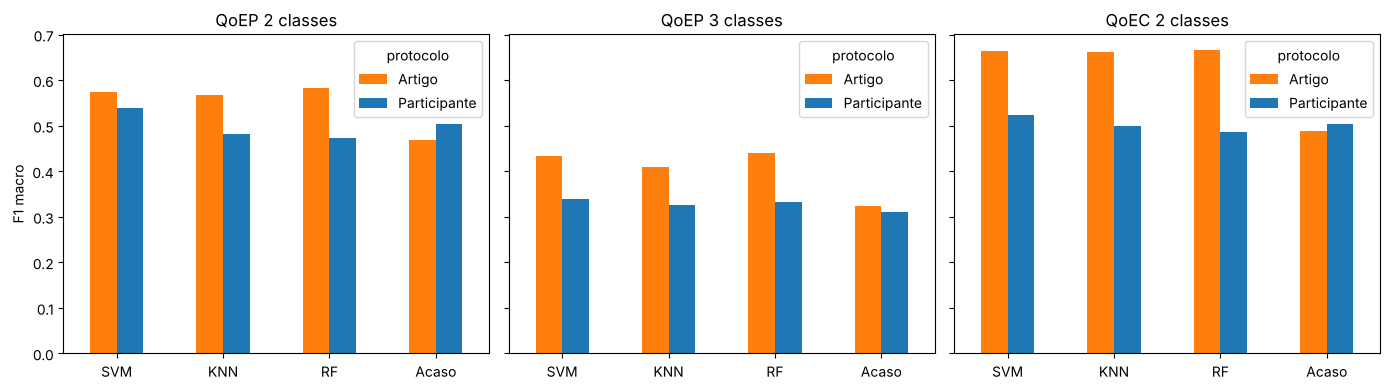

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, a in zip(axes, alvos):
    d = resultados[(resultados.alvo == a) & (resultados.features == 'Sessão')]
    d.pivot(index='modelo', columns='protocolo', values='f1').loc[list(modelos)].plot.bar(
        ax=ax, rot=0, color=['tab:orange', 'tab:blue'])
    ax.set(title=a, xlabel='', ylabel='F1 macro')
plt.tight_layout()
plt.savefig('fig_ecg_protocolos.png', dpi=150)
plt.show()